# The country list changed: can last year's regional report be rebuilt today?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-quality-governance/reference-data-versioning/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-quality-governance/reference-data-versioning/demo.ipynb)

Finance asks for last year's revenue by region, and the number no longer matches the report that went out. The
territory list changed underneath it: territories moved region, codes were renamed, split, merged, and one code was
retired and reused. This notebook builds 40 fictional territories over 36 months, publishes a regional report every
month from the table as it stood that day, then tries to rebuild those reports four ways from what is stored today.

1. The engine
2. Rebuilding the published reports
3. The reused code
4. Backdated corrections
5. As-was vs as-is
6. The split nobody can undo
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Random(209)`), every territory fictional, and
every number below matches `evidence.txt` exactly. The reference table is SCD2 (`valid_from`, `valid_to` per
version); each change also carries the month it was RECORDED, which is later than the month it took effect for 3
region moves. Sales facts carry the code that was valid on the day of the sale.

In [1]:
from __future__ import annotations

import json
import random
from collections import defaultdict
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 209


MONTHS = 36


REGIONS = ["North", "South", "East", "West", "Central"]


OPEN = 10**6


STRATEGIES = ["overwrite", "code_only", "scd2_asof", "bitemporal"]


Row = Dict[str, object]


Report = Dict[int, Dict[str, float]]


def make_codes(rng: random.Random, n: int) -> List[str]:
    out: List[str] = []
    while len(out) < n:
        c = rng.choice("BDFGKLMNPRSTVZ") + rng.choice("AEIOU") + rng.choice("BDFGKLMNPRSTVZ")
        if c not in out:
            out.append(c)
    return out


def make_world(seed: int = SEED) -> dict:
    """Reference-data events (effective month, recorded month) and the sales facts they govern."""
    rng = random.Random(seed)
    codes = make_codes(rng, 47)
    base, spare = codes[:40], codes[40:]
    init = {c: {"entity": f"T{i:02d}", "region": REGIONS[i % 5]} for i, c in enumerate(base)}
    pool = base[:]
    rng.shuffle(pool)
    ev: List[dict] = []
    other = lambda r: rng.choice([x for x in REGIONS if x != r])  # noqa: E731
    for i in range(6):  # region moves; the first three are recorded 2-4 months late (backdated)
        c, eff = pool.pop(), rng.randint(4, 28)
        ev.append({"kind": "move", "eff": eff, "rec": eff + (rng.randint(2, 4) if i < 3 else 0), "code": c,
                   "region": other(init[c]["region"])})
    for _ in range(2):  # renames: same territory, new code
        c, eff = pool.pop(), rng.randint(6, 30)
        ev.append({"kind": "rename", "eff": eff, "rec": eff, "code": c, "new": spare.pop()})
    for k in range(2):  # splits: one territory becomes two, the second in another region
        c, eff = pool.pop(), rng.randint(14, 24)
        r0 = init[c]["region"]
        ev.append({"kind": "split", "eff": eff, "rec": eff, "code": c,
                   "into": [(spare.pop(), f"S{k}a", r0), (spare.pop(), f"S{k}b", other(r0))]})
    a, b, eff = pool.pop(), pool.pop(), rng.randint(10, 26)  # merge into a new territory
    ev.append({"kind": "merge", "eff": eff, "rec": eff, "codes": [a, b], "new": spare.pop(), "entity": "M0",
               "region": init[a]["region"]})
    q, n, eff = pool.pop(), pool.pop(), rng.randint(6, 12)  # q absorbed into n, then the code q is reused
    ev.append({"kind": "absorb", "eff": eff, "rec": eff, "code": q, "into": n})
    ev.append({"kind": "create", "eff": eff + rng.randint(8, 14), "rec": None, "code": q, "entity": "R0",
               "region": other(init[n]["region"])})
    ev[-1]["rec"] = ev[-1]["eff"]
    ev.sort(key=lambda e: e["eff"])

    # sales facts, generated from the TRUE world (effective dates, not recorded ones)
    base_rev = {e: rng.uniform(50_000, 150_000) for e in [v["entity"] for v in init.values()]}
    state = {c: dict(v) for c, v in init.items()}  # code -> entity, region (true, today's knowledge irrelevant)
    facts: List[dict] = []
    for m in range(MONTHS):
        for e in [e for e in ev if e["eff"] == m]:
            if e["kind"] == "rename":
                state[e["new"]] = state.pop(e["code"])
            elif e["kind"] == "split":
                old = state.pop(e["code"])
                sh = 0.75 - 0.4 * m / e["eff"]
                for (code, ent, reg), part in zip(e["into"], (sh, 1 - sh)):
                    state[code] = {"entity": ent, "region": reg}
                    base_rev[ent] = base_rev[old["entity"]] * part
            elif e["kind"] == "merge":
                base_rev[e["entity"]] = sum(base_rev[state.pop(c)["entity"]] for c in e["codes"])
                state[e["new"]] = {"entity": e["entity"], "region": e["region"]}
            elif e["kind"] == "absorb":
                base_rev[state[e["into"]]["entity"]] += base_rev[state.pop(e["code"])["entity"]]
            elif e["kind"] == "create":
                state[e["code"]] = {"entity": e["entity"], "region": e["region"]}
                base_rev[e["entity"]] = rng.uniform(50_000, 150_000)
        split_pending = {e["code"]: e for e in ev if e["kind"] == "split" and e["eff"] > m}
        for code, s in state.items():
            amt = round(base_rev[s["entity"]] * (1 + 0.01 * m) * rng.gauss(1, 0.08))
            if code in split_pending:  # the sale happened in one of the two future halves; nobody records which
                e = split_pending[code]
                sh = 0.75 - 0.4 * m / e["eff"]
                a_amt = round(amt * sh)
                facts.append({"month": m, "code": code, "amount": a_amt, "area": e["into"][0][1]})
                facts.append({"month": m, "code": code, "amount": amt - a_amt, "area": e["into"][1][1]})
            else:
                facts.append({"month": m, "code": code, "amount": amt, "area": s["entity"]})
    return {"init": init, "events": ev, "facts": facts}


def rows_known(world: dict, t: Optional[int] = None) -> List[Row]:
    """The SCD2 reference table as it stood after month t was recorded (None = today)."""
    t = OPEN if t is None else t
    rows: List[Row] = []
    live: Dict[str, Row] = {}

    def open_(code: str, ent: str, reg: str, vf: int) -> None:
        live[code] = {"code": code, "entity": ent, "region": reg, "vf": vf, "vt": OPEN}
        rows.append(live[code])

    def close(code: str, at: int) -> Row:
        r = live.pop(code)
        r["vt"] = at
        return r

    for c, v in world["init"].items():
        open_(c, v["entity"], v["region"], 0)
    for e in world["events"]:
        if e["rec"] > t:
            continue
        m = e["eff"]
        if e["kind"] == "move":
            r = close(e["code"], m)
            open_(e["code"], r["entity"], e["region"], m)
        elif e["kind"] == "rename":
            r = close(e["code"], m)
            open_(e["new"], r["entity"], r["region"], m)
        elif e["kind"] == "split":
            close(e["code"], m)
            for code, ent, reg in e["into"]:
                open_(code, ent, reg, m)
        elif e["kind"] == "merge":
            for c in e["codes"]:
                close(c, m)
            open_(e["new"], e["entity"], e["region"], m)
        elif e["kind"] == "absorb":
            close(e["code"], m)
        elif e["kind"] == "create":
            open_(e["code"], e["entity"], e["region"], m)
    return [r for r in rows if r["vf"] < r["vt"]]


def lookup(rows: List[Row], code: str, month: Optional[int]) -> List[Row]:
    """Rows a join would match. month=None: join on code alone (every version)."""
    return [r for r in rows if r["code"] == code and (month is None or r["vf"] <= month < r["vt"])]


def report(world: dict, strategy: str) -> Tuple[Report, int]:
    """Revenue by region and month under one rebuild strategy, plus revenue the join dropped."""
    today = rows_known(world)
    current = [r for r in today if r["vt"] == OPEN]
    known = {m: rows_known(world, m) for m in range(MONTHS)}
    out: Report = defaultdict(lambda: defaultdict(float))
    lost = 0
    for f in world["facts"]:
        m = f["month"]
        hits = {"overwrite": lambda: lookup(current, f["code"], None),
                "code_only": lambda: lookup(today, f["code"], None),
                "scd2_asof": lambda: lookup(today, f["code"], m),
                "bitemporal": lambda: lookup(known[m], f["code"], m)}[strategy]()
        if not hits:
            lost += f["amount"]
        for r in hits:
            out[m][r["region"]] += f["amount"]
    return out, lost


def published(world: dict) -> Report:
    """What was actually sent each month: the table as known on the run day, as-of the sale month."""
    return report(world, "bitemporal")[0]


def successors(world: dict) -> Dict[str, List[str]]:
    """Entity lineage the reference data can carry: retired entity -> today's entities."""
    nxt: Dict[str, List[str]] = {}
    ent = {c: v["entity"] for c, v in world["init"].items()}
    for e in world["events"]:
        if e["kind"] == "rename":
            ent[e["new"]] = ent[e["code"]]
        elif e["kind"] == "split":
            nxt[ent[e["code"]]] = [x[1] for x in e["into"]]
        elif e["kind"] == "merge":
            for c in e["codes"]:
                nxt[ent[c]] = [e["entity"]]
        elif e["kind"] == "absorb":
            nxt[ent[e["code"]]] = [ent[e["into"]]]
    return nxt


def restate(world: dict, split_rule: str = "post_share") -> Report:
    """As-is: every past sale moved to the region its territory sits in TODAY, following lineage.

    A split has no unique successor; split_rule allocates it: 'post_share' by each half's revenue in the six months
    after the split, 'even' 50/50, 'truth' by the sub-area the sale really came from (unknowable in practice).
    """
    today = rows_known(world)
    region_now = {r["entity"]: r["region"] for r in today if r["vt"] == OPEN}
    nxt = successors(world)
    first6: Dict[str, float] = defaultdict(float)
    for f in world["facts"]:
        for e in world["events"]:
            if e["kind"] == "split" and e["eff"] <= f["month"] < e["eff"] + 6 and f["code"] in [x[0] for x in e["into"]]:
                first6[f["area"]] += f["amount"]
    out: Report = defaultdict(lambda: defaultdict(float))
    for f in world["facts"]:
        m = f["month"]
        if split_rule == "truth":
            ents = {f["area"]: 1.0}
        else:
            r = lookup(today, f["code"], m)[0]
            kids = nxt.get(r["entity"], [r["entity"]])
            if len(kids) == 1:
                ents = {kids[0]: 1.0}
            elif split_rule == "even":
                ents = {k: 1 / len(kids) for k in kids}
            else:
                tot = sum(first6[k] for k in kids)
                ents = {k: first6[k] / tot for k in kids}
        for e, w in ents.items():
            e = nxt.get(e, [e])[0] if e not in region_now else e
            out[m][region_now[e]] += f["amount"] * w
    return out


def cells_equal(a: Report, b: Report, tol: float) -> Tuple[int, int]:
    """(region-month cells within tol relative, months where all five are)."""
    cells = months = 0
    for m in range(MONTHS):
        ok = [abs(a[m][r] - b[m][r]) <= tol * max(1.0, abs(b[m][r])) for r in REGIONS]
        cells += sum(ok)
        months += all(ok)
    return cells, months


def study(seed: int = SEED) -> dict:
    w = make_world(seed)
    ledger = sum(f["amount"] for f in w["facts"])
    pub = published(w)
    res: dict = {"facts": len(w["facts"]), "ledger": ledger, "events": {}, "asw": {}, "asis": {}}
    for e in w["events"]:
        res["events"][e["kind"]] = res["events"].get(e["kind"], 0) + 1
    res["backdated"] = sum(1 for e in w["events"] if e["rec"] > e["eff"])
    for s in STRATEGIES:
        rep, lost = report(w, s)
        total = sum(sum(v.values()) for v in rep.values())
        c, mo = cells_equal(rep, pub, 1e-9)
        res["asw"][s] = {"cells": c, "months": mo, "reported": total / ledger, "lost": lost / ledger}
    truth = restate(w, "truth")
    for s, rep in (("overwrite", report(w, "overwrite")[0]), ("scd2_asof", pub), ("even", restate(w, "even")),
                   ("post_share", restate(w, "post_share"))):
        c, mo = cells_equal(rep, truth, 0.01)
        res["asis"][s] = {"cells": c, "months": mo}
    split_codes = {e["code"] for e in w["events"] if e["kind"] == "split"}
    pre = [f for f in w["facts"] if f["code"] in split_codes]
    pre_rev = sum(f["amount"] for f in pre)
    res["split_pre_rev"] = pre_rev / ledger
    for rule in ("even", "post_share"):
        rep = restate(w, rule)
        moved = sum(abs(rep[m][r] - truth[m][r]) for m in range(MONTHS) for r in REGIONS) / 2
        res[f"misalloc_{rule}"] = moved / pre_rev
    ab = next(e for e in w["events"] if e["kind"] == "absorb")
    cr = next(e for e in w["events"] if e["kind"] == "create")
    old_q = sum(f["amount"] for f in w["facts"] if f["code"] == ab["code"] and f["month"] < ab["eff"])
    res["reuse"] = {"code": ab["code"], "retired": ab["eff"], "reused": cr["eff"], "rev": old_q,
                    "old_region": w["init"][ab["code"]]["region"], "new_region": cr["region"]}
    res["rows_bitemporal"] = len(rows_known(w)) + sum(1 for e in w["events"] if e["rec"] > e["eff"])
    res["rows_snapshots"] = sum(sum(1 for r in rows_known(w, m) if r["vf"] <= m < r["vt"]) for m in range(MONTHS))
    return res


E = _E()
E.__dict__.update(globals())

def pct(x: float) -> str:
    return f"{100 * x:.1f}%"


def lines(r: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    ev = ", ".join(f"{v} {k}" for k, v in r["events"].items())
    w(
        f"reference-data-versioning evidence  (fictional territory list: 40 territories, 5 regions, {E.MONTHS} months; "
        f"changes: {ev}; {r['backdated']} moves recorded 2-4 months late; {r['facts']} monthly sales facts; "
        f"seeded Random({E.SEED}); every territory fictional)"
    )
    w("")
    w("1. Rebuild last year's published reports (as-was): 180 region-month cells, 36 months")
    w(f"{'strategy':<12}{'cells same':>12}{'months same':>13}{'revenue reported':>18}{'dropped by join':>17}")
    for k in E.STRATEGIES:
        a = r["asw"][k]
        w(f"{k:<12}{a['cells']:>12}{a['months']:>13}{pct(a['reported']):>18}{pct(a['lost']):>17}")
    w("overwrite = today's table only; code_only = the full history joined on code alone; scd2_asof = history joined "
      "on code and sale month; bitemporal = sale month AND what the table said on the run day")
    w("")
    w("2. The reused code")
    u = r["reuse"]
    w(f"code {u['code']} retired in month {u['retired']} (territory absorbed), reused in month {u['reused']} for a new "
      f"territory in {u['new_region']}")
    w(f"revenue sold under the old {u['code']} ({u['old_region']}), which overwrite files under {u['new_region']}   "
      f"{u['rev']:,}")
    w("")
    w("3. Backdated corrections: what valid time alone cannot reproduce")
    a = r["asw"]["scd2_asof"]
    w(f"months scd2_asof rebuilds differently from what was published   {36 - a['months']} of 36 "
      f"({180 - a['cells']} cells)")
    w(f"rows kept: bitemporal table {r['rows_bitemporal']}   vs   a monthly snapshot of the table {r['rows_snapshots']}")
    w("")
    w("4. Restate to today's regions (as-is), within 1% of the true restatement")
    w(f"{'method':<12}{'cells':>8}{'months':>9}")
    for k, v in r["asis"].items():
        w(f"{k:<12}{v['cells']:>8}{v['months']:>9}")
    w("scd2_asof is the as-was answer: correct for what was reported, wrong for a trend on today's regions")
    w("")
    w("5. The split nobody can undo")
    w(f"revenue sold under a code that later split          {pct(r['split_pre_rev'])} of all revenue")
    w(f"of it put in the wrong region, 50/50 allocation      {pct(r['misalloc_even'])}")
    w(f"of it put in the wrong region, post-split shares     {pct(r['misalloc_post_share'])}")
    w("The sale never recorded which half it came from. No rule over the reference data recovers it; only capturing "
      "the finer location on the sale does.")
    return out


def main() -> None:
    r = E.study()
    json.dump(r, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
out = lines(r)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

reference-data-versioning evidence  (fictional territory list: 40 territories, 5 regions, 36 months; changes: 6 move, 1 absorb, 2 rename, 2 split, 1 merge, 1 create; 3 moves recorded 2-4 months late; 1481 monthly sales facts; seeded Random(209); every territory fictional)


## 2. Rebuilding the published reports

Joining to today's table only (`overwrite`) reproduces 10 of 36 months and drops 6.3% of revenue: sales under codes
that were renamed, split or merged away find no row. Joining the full history on the code alone (`code_only`)
drops nothing and reports 115.7% of revenue, because every code that ever changed matches several versions and the
sale is counted once per version - it reproduces no month at all. The as-of join (`scd2_asof`) gets every dollar
and 29 of 36 months. Only the bitemporal join reproduces all 36.

In [3]:
print("\n".join(section(1)))

Rebuild last year's published reports (as-was): 180 region-month cells, 36 months
strategy      cells same  months same  revenue reported  dropped by join
overwrite             57           10             93.7%             6.3%
code_only             53            0            115.7%             0.0%
scd2_asof            165           29            100.0%             0.0%
bitemporal           180           36            100.0%             0.0%
overwrite = today's table only; code_only = the full history joined on code alone; scd2_asof = history joined on code and sale month; bitemporal = sale month AND what the table said on the run day


## 3. The reused code

A retired code that comes back for a different territory is the quiet one: nothing errors. Today's table knows
only the new owner, so `overwrite` files the old territory's whole history under the new territory's region.

In [4]:
print("\n".join(section(2)))

The reused code
code RID retired in month 9 (territory absorbed), reused in month 20 for a new territory in North
revenue sold under the old RID (South), which overwrite files under North   526,934


## 4. Backdated corrections

An SCD2 table records when a change was valid, not when anybody knew it. Three region moves were keyed in 2-4
months after they took effect, so the reports for those months went out with the old region. The as-of join on
today's table quietly rewrites them: 7 of 36 months (15 cells) no longer match what was sent. A second time axis
(when the row was recorded) fixes it at the cost of a handful of rows; storing a monthly snapshot of the whole table
does too, at 25 times the rows.

In [5]:
print("\n".join(section(3)))

Backdated corrections: what valid time alone cannot reproduce
months scd2_asof rebuilds differently from what was published   7 of 36 (15 cells)
rows kept: bitemporal table 57   vs   a monthly snapshot of the table 1445


## 5. As-was vs as-is

"Last year by region" has two right answers. As-was is what was reported. As-is moves every past sale to the
region its territory sits in today, so a trend line compares like with like. They differ: the as-was rebuild sits
within 1% of the true as-is restatement in only 61 of 180 cells. The failure is not picking one; it is not knowing
which one a number is.

In [6]:
print("\n".join(section(4)))

Restate to today's regions (as-is), within 1% of the true restatement
method         cells   months
overwrite         96       13
scd2_asof         61       10
even             153       22
post_share       137       18
scd2_asof is the as-was answer: correct for what was reported, wrong for a trend on today's regions


## 6. The split nobody can undo

To restate a split territory to today's regions, each old sale must be given to one of the two halves, and the sale
never recorded which. A 50/50 rule puts 10.2% of that revenue in the wrong region; allocating by each half's share
after the split does worse, 20.5%, because the mix drifted in the years before the split (by construction here, and
commonly in practice: the split usually happens because one half grew). This is the negative result: no rule over
the reference data recovers it. Only capturing the finer location on the sale itself does.

In [7]:
print("\n".join(section(5)))

The split nobody can undo
revenue sold under a code that later split          1.7% of all revenue
of it put in the wrong region, 50/50 allocation      10.2%
of it put in the wrong region, post-split shares     20.5%
The sale never recorded which half it came from. No rule over the reference data recovers it; only capturing the finer location on the sale does.


## 7. The chart

The full figure, with the reused-code mechanism drawn, is `audit.png` (built by `make_chart.py`).

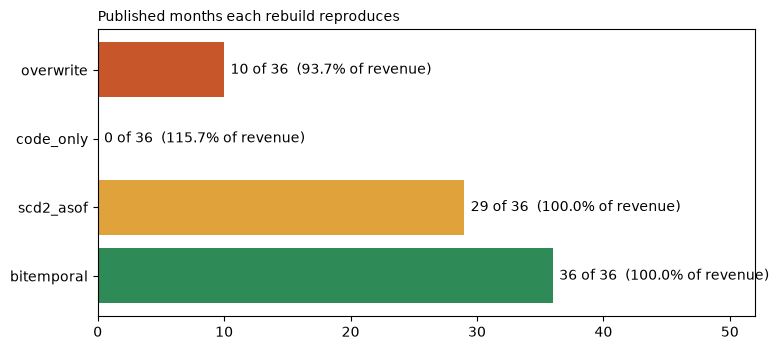

In [8]:
names = list(r["asw"])
fig, ax = plt.subplots(figsize=(8, 3.6))
months = [r["asw"][k]["months"] for k in names]
ax.barh(names[::-1], months[::-1], color=["#2e8b57", "#e0a23a", "#c8562b", "#c8562b"])
for i, k in enumerate(names[::-1]):
    a = r["asw"][k]
    ax.text(a["months"] + 0.5, i, f"{a['months']} of 36  ({100 * a['reported']:.1f}% of revenue)", va="center")
ax.set_xlim(0, 52)
ax.set_title("Published months each rebuild reproduces", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Today's table alone reproduces 10 of 36 months and drops 6.3% of revenue; a code-only history join reports 115.7%.
- A reused code files the old territory's history under the new one, with no error.
- Valid time alone misses every month whose change was recorded late; add a recorded-time axis.
- As-was and as-is are both right answers to different questions: label which one every report is.
- A split cannot be restated from reference data: capture the finer location on the sale.

## 8. Try your own

In [9]:
# w = make_world(seed=1)                       # another fictional territory history
# for e in w["events"]: print(e)
# rep, lost = report(w, "scd2_asof")
# print(dict(rep[20]), lost)

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version rebuilds any
month four ways next to what was published: `pip install -r requirements.txt && streamlit run app.py`.